# Chapitre 2 - Lab : tables, JSONB et requêtes récursives dans PostgreSQL

Ce lab confronte le cours à une vraie base relationnelle qui sait aussi stocker des
documents : PostgreSQL 16 et son type **JSONB** (JSON stocké sous forme binaire
décomposée, indexable). Nous allons :

1. ranger les mêmes CV en tables normalisées et en documents JSONB, et comparer leur
   taille ;
2. lire un profil complet : plusieurs requêtes, une jointure, un document, un agrégat
   JSON calculé par le serveur ;
3. indexer des valeurs **imbriquées** dans les documents (index GIN) pour interroger une
   relation plusieurs-à-plusieurs dans les deux sens ;
4. mesurer le prix de la localité : une petite modification dans un gros document,
   comptée en octets de journal (WAL) ;
5. migrer un schéma : ce qui est instantané et ce qui réécrit la table ;
6. stocker un graphe dans deux tables et l'interroger avec `WITH RECURSIVE`, y compris
   la détection de cycles.

**Démarrer et arrêter les services** (depuis la racine du dépôt) :

```bash
docker compose -f docker/datamodels/compose.yml -p ddia_datamodels up -d     # démarrer
docker compose -f docker/datamodels/compose.yml -p ddia_datamodels down -v   # arrêter et effacer
```

PostgreSQL écoute sur le port **10332** de la machine (utilisateur, mot de passe et base :
`ddia` / `ddia` / `modeles`).

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg
from psycopg.types.json import Jsonb

from ddia import datamodels as dm
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 120)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

DSN = "host=localhost port=10332 user=ddia password=ddia dbname=modeles"
con = None
for essai in range(30):
    try:
        con = psycopg.connect(DSN, autocommit=True)
        break
    except psycopg.OperationalError:
        time.sleep(1)
assert con is not None, "PostgreSQL ne répond pas : avez-vous lancé docker compose up ?"
print(con.execute("SELECT version()").fetchone()[0][:60])


def q(sql, params=None):
    return con.execute(sql, params).fetchall()


def plan(sql, params=None):
    return "\n".join(r[0] for r in q("EXPLAIN (ANALYZE, BUFFERS, TIMING OFF, SUMMARY OFF) " + sql, params))


def wal_bytes(fn):
    """Octets de journal (WAL) écrits pendant fn()."""
    a = q("SELECT pg_current_wal_lsn()")[0][0]
    fn()
    b = q("SELECT pg_current_wal_lsn()")[0][0]
    return float(q("SELECT pg_wal_lsn_diff(%s, %s)", (b, a))[0][0])

PostgreSQL 16.14 (Debian 16.14-1.pgdg13+1) on x86_64-pc-linu


## 1. Les mêmes CV en tables et en documents (section *The Object-Relational Mismatch*)

On génère 50 000 profils synthétiques (`dm.make_profiles`) et on les range deux fois :
dans le schéma normalisé du cours 1 (cinq tables), et dans une table `profiles` à une
colonne `doc JSONB`.

In [2]:
orgs = dm.make_orgs(200, seed=0)
profiles = dm.make_profiles(50_000, seed=0, orgs=orgs)
con.execute("""
DROP TABLE IF EXISTS positions, education, contact_info, users, organizations, regions, profiles CASCADE;
CREATE TABLE regions (id text PRIMARY KEY, name text);
CREATE TABLE organizations (id int PRIMARY KEY, name text, logo_url text);
CREATE TABLE users (id int PRIMARY KEY, first_name text, last_name text, headline text,
                    region_id text REFERENCES regions, photo_url text);
CREATE TABLE positions (id serial PRIMARY KEY, user_id int REFERENCES users, job_title text,
                        org_id int REFERENCES organizations, start_year int, end_year int);
CREATE TABLE education (id serial PRIMARY KEY, user_id int REFERENCES users, school_name text,
                        start_year int, end_year int);
CREATE TABLE contact_info (user_id int REFERENCES users, kind text, value text);
CREATE TABLE profiles (user_id int PRIMARY KEY, doc jsonb);
""")
with con.cursor() as cur:
    with cur.copy("COPY regions FROM STDIN") as cp:
        for k, v in dm.REGIONS.items():
            cp.write_row((k, v))
    with cur.copy("COPY organizations FROM STDIN") as cp:
        for o in orgs:
            cp.write_row((o["org_id"], o["name"], o["logo_url"]))
    with cur.copy("COPY users FROM STDIN") as cp:
        for p in profiles:
            cp.write_row((p["user_id"], p["first_name"], p["last_name"], p["headline"], p["region_id"], p["photo_url"]))
    with cur.copy("COPY positions (user_id, job_title, org_id, start_year, end_year) FROM STDIN") as cp:
        for p in profiles:
            for x in p["positions"]:
                cp.write_row((p["user_id"], x["job_title"], x["org_id"], x["start"], x["end"]))
    with cur.copy("COPY education (user_id, school_name, start_year, end_year) FROM STDIN") as cp:
        for p in profiles:
            for x in p["education"]:
                cp.write_row((p["user_id"], x["school_name"], x["start"], x["end"]))
    with cur.copy("COPY contact_info FROM STDIN") as cp:
        for p in profiles:
            for k, v in p["contact_info"].items():
                cp.write_row((p["user_id"], k, v))
    with cur.copy("COPY profiles FROM STDIN") as cp:
        for p in profiles:
            cp.write_row((p["user_id"], json.dumps(p, ensure_ascii=False)))
con.execute("""
CREATE INDEX positions_user ON positions (user_id);
CREATE INDEX education_user ON education (user_id);
CREATE INDEX contact_user ON contact_info (user_id);
""")
con.execute("VACUUM ANALYZE")
tailles = pd.DataFrame(q("""
SELECT relname, (xpath('/row/c/text()', query_to_xml('SELECT count(*) AS c FROM ' || relname, false, true, '')))[1]::text::int,
       pg_size_pretty(pg_table_size(relid)) AS donnees,
       pg_size_pretty(pg_indexes_size(relid)) AS index, pg_total_relation_size(relid) AS total
  FROM pg_stat_user_tables WHERE relname IN ('users','positions','education','contact_info','profiles')
 ORDER BY relname"""), columns=["table", "lignes", "données", "index", "total (octets)"])
tailles

,table,lignes,données,index,total (octets)
0,contact_info,75330,5376 kB,1392 kB,6930432
1,education,74770,5224 kB,3040 kB,8462336
2,positions,175210,12 MB,6232 kB,18546688
3,profiles,50000,48 MB,1112 kB,51191808
4,users,50000,4968 kB,1112 kB,6225920


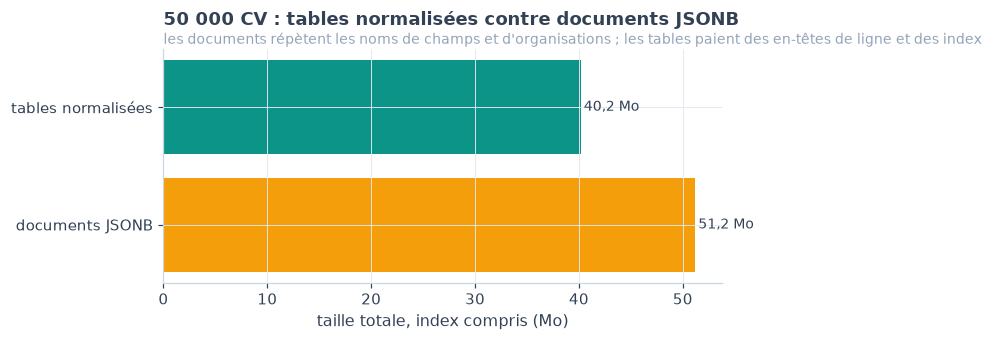

In [3]:
norm = tailles[tailles.table != "profiles"]["total (octets)"].sum()
docs = tailles[tailles.table == "profiles"]["total (octets)"].sum()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(["documents JSONB", "tables normalisées"], [docs / 1e6, norm / 1e6], color=[AMBER, TEAL])
for i, v in enumerate([docs, norm]):
    ax.text(v / 1e6 + 0.3, i, f"{v / 1e6:.1f} Mo".replace(".", ","), va="center", fontsize=9)
ax.set_xlabel("taille totale, index compris (Mo)")
ax.set_title("50 000 CV : tables normalisées contre documents JSONB")
subtitle(ax, "les documents répètent les noms de champs et d'organisations ; les tables paient des en-têtes de ligne et des index")
plt.tight_layout(); plt.show()

Les deux représentations ont des tailles du même ordre (les documents un peu plus
gros) : les documents répètent dans
chaque profil les **noms de champs** et le nom des organisations (dénormalisé), les tables
paient un en-tête d'environ 24 octets par ligne, les clés étrangères répétées et les index
sur `user_id`.

> **À retenir.** PostgreSQL range aussi bien des tables que des documents JSONB ; la
> différence de taille reste modeste, la vraie différence est dans les accès.